# Gait as a Window into the Brain
### Psychointelligence: detecting cognitive decline, falls and frailty from how a person walks

**Dataset:** GSTRIDE  ·  163 older adults  ·  **Built in Google Colab**

Every step explains *what* we are doing and *why*

**Steps Overview:**
1. Load and look at the raw data
2. Clean it properly
3. Visualise it with doughnut charts
4. Remove redundant (overlapping) features
5. Train three algorithms on three tasks
6. Measure how well they did
7. Read what the best model learned
8. Show how the three tasks relate

> **The big idea:** walking is not fully automatic. Staying steady needs attention, planning and balance, which are all brain jobs. So when the brain starts to struggle, the walk quietly changes. We test whether a machine can pick that up.

## Step 0 — Set up our tools

We load the libraries and define a house style

In [1]:
import pandas as pd, numpy as np, re, warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, cross_val_predict, StratifiedKFold
from sklearn.metrics import roc_curve, auc, confusion_matrix
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import pearsonr, spearmanr
import statsmodels.api as sm

RANDOM_STATE = 42

# ---- house style ----
INK="#243746"; PRIMARY="#0B6E99"; TEAL="#1C7293"; AMBER="#E08A2B"
POS="#C43E3E"; NEG="#2E86AB"; GREEN="#2E8B57"; PURPLE="#7D5BA6"; GREY="#AEB9C2"
CATS=[PRIMARY, AMBER, TEAL, POS, GREEN, PURPLE]
plt.rcParams.update({"font.size":11, "axes.titlesize":13, "axes.titleweight":"bold",
                     "axes.edgecolor":"#C9D3DA", "axes.labelcolor":INK,
                     "text.color":INK, "xtick.color":INK, "ytick.color":INK,
                     "figure.facecolor":"white", "axes.facecolor":"white"})

def style_ax(ax):
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)

def doughnut(ax, sizes, labels, colors, title, center_text):
    ax.pie(sizes, labels=labels, colors=colors, startangle=90,
           autopct=lambda p: f"{p:.0f}%", pctdistance=0.75, labeldistance=1.12,
           wedgeprops=dict(width=0.42, edgecolor="white", linewidth=2),
           textprops=dict(fontsize=10, color=INK))
    ax.text(0, 0, center_text, ha="center", va="center", fontsize=13, fontweight="bold", color=INK)
    ax.set_title(title, fontsize=12, fontweight="bold", color=INK, pad=8)

def hbar(ax, labels, values, colors, title, xlabel):
    ax.barh(labels, values, color=colors)
    ax.set_title(title); ax.set_xlabel(xlabel); style_ax(ax)
    ax.invert_yaxis()

# ---- added for the ICOIN 2027 revision ----
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.calibration import calibration_curve
N_REPEATS = 10   # repeat 5-fold CV 10 times, as in Step 9

def lr_pipeline(middle_steps=None):
    """The same logistic regression as Step 9. Extra steps (e.g. VIF) go between imputer and scaler."""
    steps = [("imp", SimpleImputer(strategy="median"))] + (middle_steps or [])
    steps += [("sc", StandardScaler()),
              ("m", LogisticRegression(C=0.5, class_weight="balanced", max_iter=2000))]
    return Pipeline(steps)

def run_cv(model, Xdata, y, n_repeats=N_REPEATS):
    """Repeated 5-fold CV. Returns out-of-fold probabilities, one row per repeat."""
    Xdata = np.asarray(Xdata, dtype=float); y = np.asarray(y).astype(int)
    P = np.zeros((n_repeats, len(y)))
    for r in range(n_repeats):
        skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE + r)
        P[r] = cross_val_predict(clone(model), Xdata, y, cv=skf, method="predict_proba")[:, 1]
    return P

def auc_with_ci(y, P, n_boot=2000, seed=RANDOM_STATE):
    """AUC = mean over repeats. 95% CI = bootstrap over people (and repeats)."""
    y = np.asarray(y).astype(int)
    point = np.mean([roc_auc_score(y, p) for p in P])
    rng = np.random.default_rng(seed); boots = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y)); r = rng.integers(0, len(P))
        if len(np.unique(y[i])) == 2:
            boots.append(roc_auc_score(y[i], P[r, i]))
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return point, lo, hi

def auc_gain_ci(y, P_small, P_big, n_boot=2000, seed=RANDOM_STATE):
    """How much AUC the bigger model adds over the smaller one, with a paired bootstrap 95% CI."""
    y = np.asarray(y).astype(int)
    point = np.mean([roc_auc_score(y, b) - roc_auc_score(y, s) for s, b in zip(P_small, P_big)])
    rng = np.random.default_rng(seed); boots = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y)); r = rng.integers(0, len(P_small))
        if len(np.unique(y[i])) == 2:
            boots.append(roc_auc_score(y[i], P_big[r, i]) - roc_auc_score(y[i], P_small[r, i]))
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return point, lo, hi

def screen_stats(y, P, thr=0.5):
    """Confusion-matrix counts and rates at one threshold, averaged over the repeats."""
    y = np.asarray(y).astype(int); rows = []
    for p in P:
        tn, fp, fn, tp = confusion_matrix(y, (p >= thr).astype(int), labels=[0, 1]).ravel()
        rows.append([tp, fn, fp, tn])
    tp, fn, fp, tn = np.mean(rows, axis=0)
    return {"TP": int(round(tp)), "FN": int(round(fn)), "FP": int(round(fp)), "TN": int(round(tn)),
            "Sensitivity": float(round(tp / (tp + fn), 3)),
            "Specificity": float(round(tn / (tn + fp), 3)),
            "Precision": float(round(tp / (tp + fp), 3)) if (tp + fp) else float("nan"),
            "Referred (%)": float(round(100 * (tp + fp) / len(y), 1))}

class VIFSelector(BaseEstimator, TransformerMixin):
    """Drops the most redundant feature until every VIF is below the limit.
    It learns ONLY from the training fold it is fitted on, so test people never leak in."""
    def __init__(self, limit=5.0):
        self.limit = limit
    def fit(self, X, y=None):
        Z = np.asarray(X, dtype=float)
        Z = (Z - Z.mean(0)) / Z.std(0)
        keep = list(range(Z.shape[1]))
        while len(keep) > 1:
            vifs = [variance_inflation_factor(Z[:, keep], i) for i in range(len(keep))]
            worst = int(np.argmax(vifs))
            if vifs[worst] < self.limit:
                break
            keep.pop(worst)
        self.keep_ = keep
        return self
    def transform(self, X):
        return np.asarray(X, dtype=float)[:, self.keep_]

print("Tools ready (including revision helpers).")

Tools ready (including revision helpers).


## Step 1 — Load the data

Upload the data `Database_register.xlsx` 163 people record

In [2]:
DATA_PATH = "/kaggle/input/datasets/collinslemeke/gstride-gait-frailty-and-cognitive-dataset/Database_register.xlsx"

def load_register(path):
    if str(path).lower().endswith(".csv"):
        full = pd.read_csv(path, sep=";", encoding="cp1252", header=None)
    else:
        full = pd.read_excel(path, header=None)
    colnames = full.iloc[1].tolist()
    data = full.iloc[3:].copy()
    data.columns = colnames
    data = data.dropna(how="all").reset_index(drop=True)
    return data, colnames

df, cols = load_register(DATA_PATH)
print(f"Loaded {df.shape[0]} people, each described by {df.shape[1]} columns.")

Loaded 163 people, each described by 60 columns.


## Step 2 — A first look at the raw data

Two questions matter most at the start:
- **How complete is the data?** (missing values cause trouble later)
- **What do a few rows actually look like?**

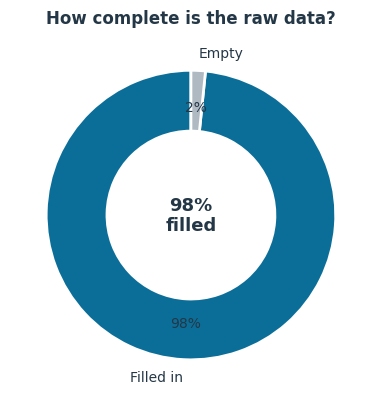

Most columns are complete. The few gaps are handled in Step 7.


In [3]:
# a tiny helper to find columns by keyword (the names have odd spacing)
def one(key):
    hits = [c for c in cols if isinstance(c, str) and key.lower() in c.lower()]
    return hits[0] if hits else None
def num(c):
    return pd.to_numeric(df[c], errors="coerce")

# how full is the whole table?
total_cells = df.shape[0] * df.shape[1]
filled = df.notna().sum().sum()
missing = total_cells - filled

fig, ax = plt.subplots(figsize=(4.2, 4.2))
doughnut(ax, [filled, missing], ["Filled in", "Empty"], [PRIMARY, GREY],
         "How complete is the raw data?", f"{100*filled/total_cells:.0f}%\nfilled")
plt.tight_layout(); plt.show()

print("Most columns are complete. The few gaps are handled in Step 7.")

## Step 3 — Clean the data

Real data always has small messes. We fix three:

1. **The fall label** has a stray space (`"NO "` vs `"NO"`), which would split one group into two. We trim it and turn Yes/No into 1/0.
2. **Age** is stored as bands like `70-74`. We use the middle value (72).
3. We build our **three yes/no targets** (the things we will try to predict).

The three targets:
- **Dementia** = signs of cognitive decline (a score called GDS of 3 or more)
- **Falls** = fell in the last year
- **Frailty** = physically frail (a score called Fried of 2 or more)

In [4]:
def age_midpoint(v):
    ns = re.findall(r"\d+", str(v))
    return np.mean([int(x) for x in ns]) if ns else np.nan

gds   = pd.to_numeric(df[one("Global Deterioration")], errors="coerce")
fried = pd.to_numeric(df[one("Frailty assessment")], errors="coerce")
fall_raw = df[one("Falls during the last year")]
print("Fall label BEFORE cleaning:", list(fall_raw.unique()))
fall = fall_raw.astype(str).str.strip().str.upper().map({"YES":1, "NO":0})
print("Fall label AFTER cleaning :", dict(fall.value_counts()))

TARGETS = {
    "Dementia": (gds  >= 3).astype(int),
    "Falls":    fall.astype(int),
    "Frailty":  (fried >= 2).astype(int),
}
print("\nTargets built. Positive counts (people who HAVE the condition):")
for name, y in TARGETS.items():
    print(f"  {name:<10} {int(y.sum()):>3} of {len(y)}")

Fall label BEFORE cleaning: ['NO', 'YES', 'NO ']
Fall label AFTER cleaning : {1: np.int64(86), 0: np.int64(77)}

Targets built. Positive counts (people who HAVE the condition):
  Dementia    43 of 163
  Falls       86 of 163
  Frailty     49 of 163


## Step 4 — Visualise the three targets (doughnut charts)

A model's job is easier or harder depending on how **balanced** the groups are. If only a few people have a condition, the model has fewer examples to learn from. These doughnuts show that split for each task.

**How to read them:** the coloured slice is the share of people who *have* the condition. Falls is near an even 50/50, dementia is the most lopsided.

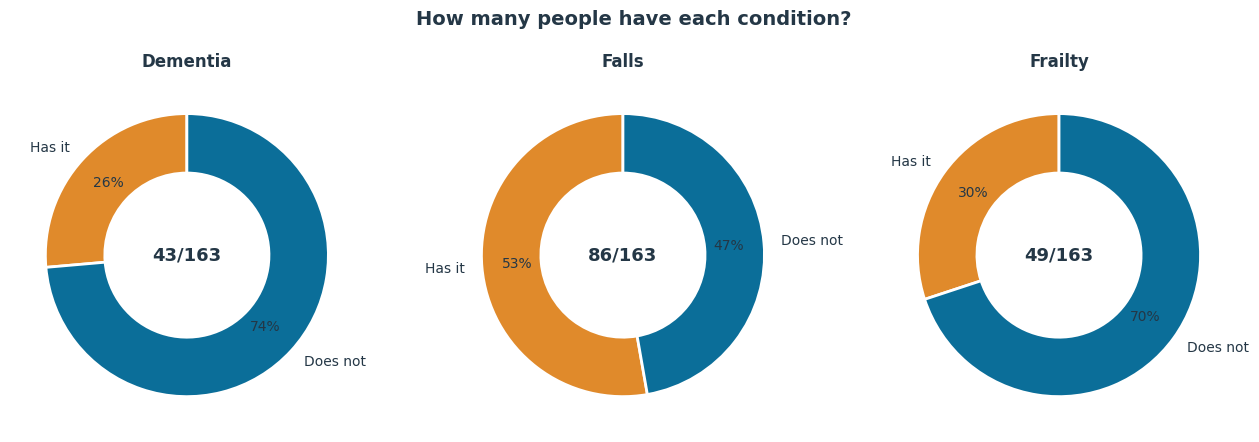

Falls is the most balanced (53% positive); dementia is the rarest (26%).
Rare = harder to learn, so we watch dementia results especially carefully.


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))
for ax, (name, y) in zip(axes, TARGETS.items()):
    pos = int(y.sum()); neg = len(y) - pos
    doughnut(ax, [pos, neg], ["Has it", "Does not"], [AMBER, PRIMARY],
             name, f"{pos}/{len(y)}")
fig.suptitle("How many people have each condition?", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

print("Falls is the most balanced (53% positive); dementia is the rarest (26%).")
print("Rare = harder to learn, so we watch dementia results especially carefully.")

## Step 5 — Who is in the study?

Knowing the make-up of the group tells us who our conclusions apply to. Two doughnuts and one bar chart:

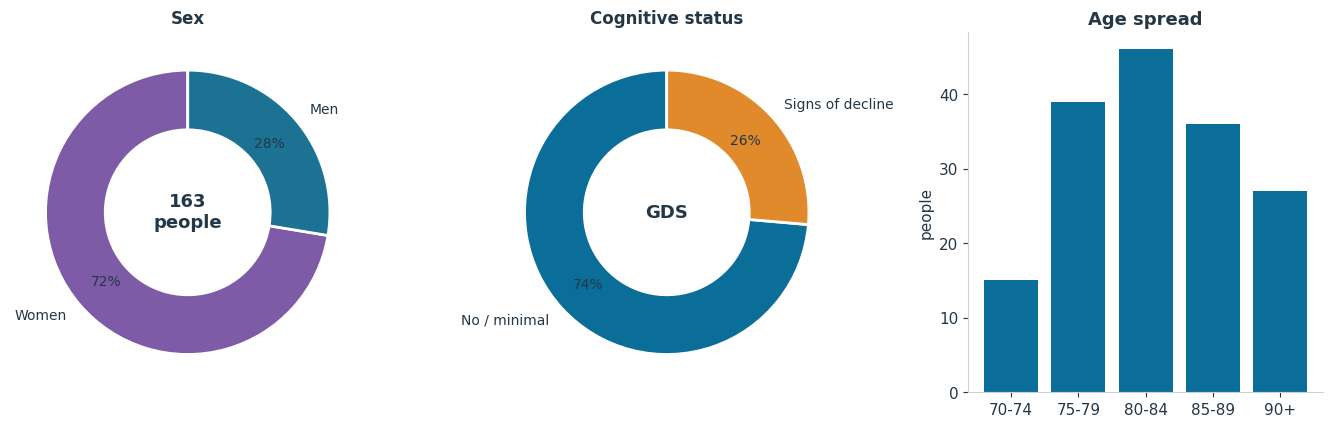

Mostly women, mostly aged 80+, and about a quarter show signs of cognitive decline.


In [6]:
sex = df[one("Sex")].astype(str).str.strip().str.upper()
sex_counts = sex.value_counts()

# group cognitive stage into an easy two-way split
cog_group = pd.Series(np.where(gds>=3, "Signs of decline", "No/minimal decline"))
cog_counts = cog_group.value_counts()

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.4))
doughnut(axes[0], [sex_counts.get("F",0), sex_counts.get("M",0)],
         ["Women", "Men"], [PURPLE, TEAL], "Sex", f"{len(sex)}\npeople")
doughnut(axes[1], [cog_counts.get("No/minimal decline",0), cog_counts.get("Signs of decline",0)],
         ["No / minimal", "Signs of decline"], [PRIMARY, AMBER], "Cognitive status", "GDS")

# age bands as a bar (too many categories for a doughnut)
age_mid = df[one("Age (range")].map(age_midpoint)
bands = pd.cut(age_mid, bins=[69,74,79,84,89,99], labels=["70-74","75-79","80-84","85-89","90+"])
band_counts = bands.value_counts().sort_index()
axes[2].bar(band_counts.index.astype(str), band_counts.values, color=PRIMARY)
axes[2].set_title("Age spread"); axes[2].set_ylabel("people"); style_ax(axes[2])
plt.tight_layout(); plt.show()

print("Mostly women, mostly aged 80+, and about a quarter show signs of cognitive decline.")

## Step 6 — Choose the walking measurements, and remove overlaps

The sensor in the data gives many walking numbers, but some are **the same information in disguise**. For example, walking speed is roughly *stride length x cadence*, so putting all three in confuses the model, like giving it height in centimetres, inches and feet at once.

We start with a candidate list, then run two checks:
- a **correlation heatmap** (which features move together), and
- a **VIF score** (a redundancy meter: above 5 is a warning, above 10 is severe).

Then we keep one clean representative from each overlapping group.

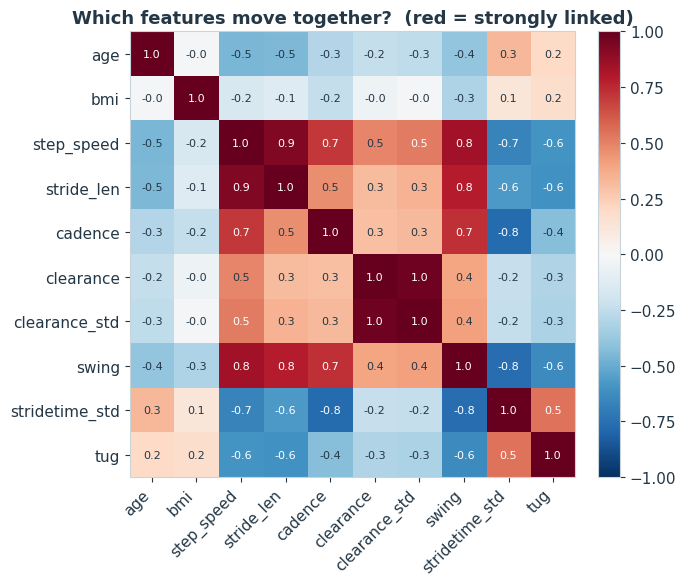

In [7]:
# candidate features (the full, overlapping set)
cand = pd.DataFrame(index=df.index)
cand["age"]            = age_mid
cand["bmi"]            = num(one("Body-mass"))
cand["step_speed"]     = num(one("Step Speed - Avg"))
cand["stride_len"]     = num(one("Stride Length - Avg"))
cand["cadence"]        = num(one("Cadence - Avg"))
cand["clearance"]      = num(one("Clearance - Avg"))
cand["clearance_std"]  = num(one("Clearance - STD"))
cand["swing"]          = num(one("Swing - Avg"))
cand["stridetime_std"] = num(one("Stride time - STD"))
cand["tug"]            = num(one("TUG test"))

C = cand.fillna(cand.median())

# --- correlation heatmap ---
fig, ax = plt.subplots(figsize=(7.2, 6))
corr = C.corr()
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(C.columns))); ax.set_xticklabels(C.columns, rotation=45, ha="right")
ax.set_yticks(range(len(C.columns))); ax.set_yticklabels(C.columns)
for i in range(len(C.columns)):
    for j in range(len(C.columns)):
        ax.text(j, i, f"{corr.iloc[i,j]:.1f}", ha="center", va="center",
                color="white" if abs(corr.iloc[i,j])>0.5 else INK, fontsize=8)
ax.set_title("Which features move together?  (red = strongly linked)")
plt.colorbar(im, fraction=0.046, pad=0.04); plt.tight_layout(); plt.show()

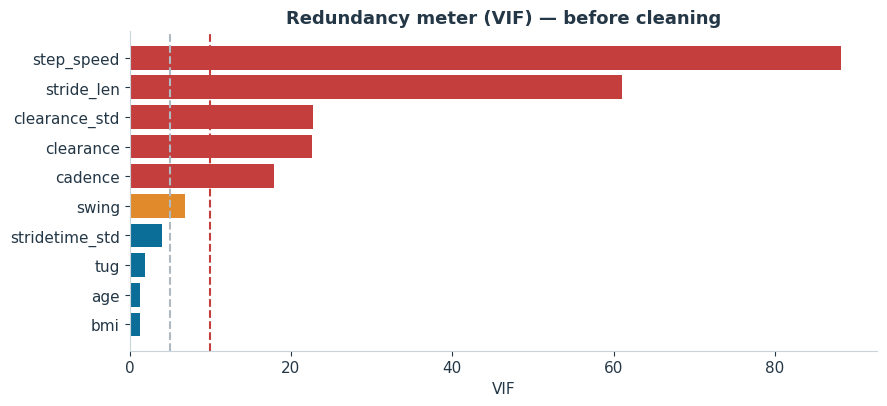

Red bars are badly overlapping features. speed, stride length, cadence and clearance
all carry the same 'how well do they walk' information, so we keep just representatives.


In [8]:
# --- VIF redundancy meter ---
from sklearn.preprocessing import StandardScaler as _SS
Cs = _SS().fit_transform(C)
vif = pd.DataFrame({"feature": C.columns,
                    "VIF": [variance_inflation_factor(Cs, i) for i in range(Cs.shape[1])]}
                   ).sort_values("VIF", ascending=False)

colors = [POS if v>10 else (AMBER if v>5 else PRIMARY) for v in vif["VIF"]]
fig, ax = plt.subplots(figsize=(9, 4.2))
hbar(ax, vif["feature"], vif["VIF"], colors, "Redundancy meter (VIF) — before cleaning", "VIF")
ax.axvline(5, color=GREY, ls="--"); ax.axvline(10, color=POS, ls="--")
plt.tight_layout(); plt.show()
print("Red bars are badly overlapping features. speed, stride length, cadence and clearance")
print("all carry the same 'how well do they walk' information, so we keep just representatives.")

**The decision.** From the tangled walking cluster we keep two representatives (**step speed** and **foot clearance**), drop the duplicates (stride length, cadence, clearance variability, swing), and keep the independent features (age, BMI, TUG, stride-time variability). This is our **clean feature set of 6**.

In [9]:
FEATURES = ["age", "bmi", "tug", "step_speed", "clearance", "stridetime_std"]
X = cand[FEATURES].copy()

# confirm the redundancy is gone
Xs_check = _SS().fit_transform(X.fillna(X.median()))
vif2 = pd.DataFrame({"feature": FEATURES,
                     "VIF": [variance_inflation_factor(Xs_check, i) for i in range(len(FEATURES))]})
print("Clean feature set:", FEATURES)
print("\nVIF after cleaning (all should be under 5 now):")
for _, r in vif2.iterrows():
    print(f"  {r['feature']:<16} {r['VIF']:.1f}")

Clean feature set: ['age', 'bmi', 'tug', 'step_speed', 'clearance', 'stridetime_std']

VIF after cleaning (all should be under 5 now):
  age              1.3
  bmi              1.0
  tug              1.7
  step_speed       2.9
  clearance        1.3
  stridetime_std   2.0


### Step 6b — Does the feature choice leak information? (Reviewer 1, point 6)

Above, we chose the 6 features using VIF on all 163 people. A reviewer asked whether this lets the test people influence the model.

To check, we run the model two ways:
- **A)** our 6 chosen features, as in the paper
- **B)** all 10 candidate features, with VIF choosing them again **inside every training fold**, so the test people are never seen

If A and B give similar AUC, the original feature choice did not inflate the results.

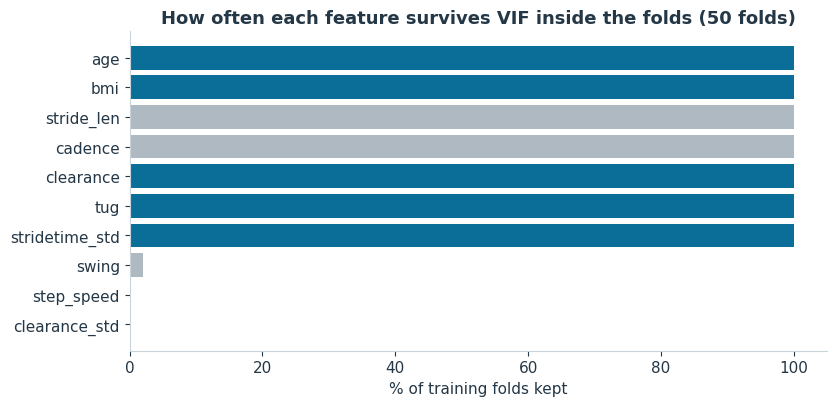

A) Fixed 6 features (paper):     AUC 0.747  (95% CI 0.660 to 0.828)
B) VIF inside each fold:         AUC 0.746  (95% CI 0.654 to 0.832)
   Difference (B minus A):       -0.000  (95% CI -0.028 to +0.031)

Blue bars = the 6 features used in the paper. Grey = features we dropped.
If A and B are close, the original feature choice did not inflate the results.


In [10]:
# ===== Step 6b: Check that VIF selection does not leak (Reviewer 1, point 6) =====
y_cog = TARGETS["Dementia"].values.astype(int)   # cognitive decline = GDS >= 3 (used from here on)
ALL_CANDIDATES = list(cand.columns)               # the 10 features BEFORE VIF

# A) Your 6 chosen features, exactly as in the paper
P_fixed = run_cv(lr_pipeline(), cand[FEATURES], y_cog)

# B) Start again from all 10 candidates. VIF now chooses the features
#    inside EVERY training fold, so the test people never influence the choice.
P_infold = run_cv(lr_pipeline([("vif", VIFSelector(limit=5.0))]), cand[ALL_CANDIDATES], y_cog)

a_fix, lo_fix, hi_fix = auc_with_ci(y_cog, P_fixed)
a_in,  lo_in,  hi_in  = auc_with_ci(y_cog, P_infold)
d, d_lo, d_hi = auc_gain_ci(y_cog, P_fixed, P_infold)

# How often does each feature survive VIF across all training folds?
Xc = cand[ALL_CANDIDATES].values.astype(float)
kept_count = pd.Series(0, index=ALL_CANDIDATES); n_folds = 0
for r in range(N_REPEATS):
    skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE + r)
    for tr, te in skf.split(Xc, y_cog):
        imp = SimpleImputer(strategy="median").fit(Xc[tr])
        sel = VIFSelector(limit=5.0).fit(imp.transform(Xc[tr]))
        kept_count.iloc[sel.keep_] += 1
        n_folds += 1
kept_pct = (100 * kept_count / n_folds).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
hbar(ax, kept_pct.index, kept_pct.values,
     [PRIMARY if f in FEATURES else GREY for f in kept_pct.index],
     f"How often each feature survives VIF inside the folds ({n_folds} folds)", "% of training folds kept")
plt.tight_layout(); plt.show()

print(f"A) Fixed 6 features (paper):     AUC {a_fix:.3f}  (95% CI {lo_fix:.3f} to {hi_fix:.3f})")
print(f"B) VIF inside each fold:         AUC {a_in:.3f}  (95% CI {lo_in:.3f} to {hi_in:.3f})")
print(f"   Difference (B minus A):       {d:+.3f}  (95% CI {d_lo:+.3f} to {d_hi:+.3f})")
print("\nBlue bars = the 6 features used in the paper. Grey = features we dropped.")
print("If A and B are close, the original feature choice did not inflate the results.")

## Step 7 — Handle the missing values

A few people are missing the TUG measurement. So we fill each gap with that column's **median** (its middle value), a safe, standard choice. This chart shows below shows the feature missing value.

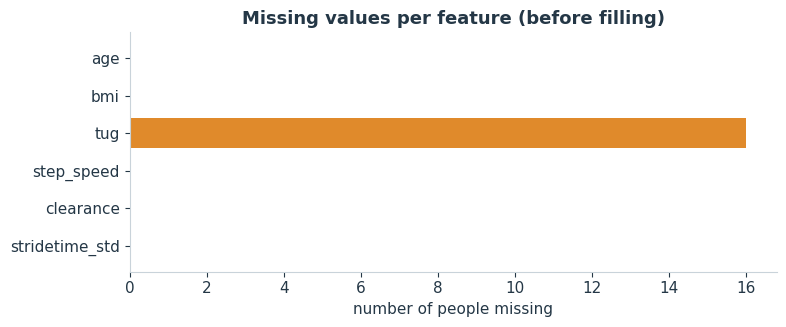

Only TUG has gaps. We fill them with the median inside the modelling pipeline,
so the fill is learned only from training data


In [11]:
miss = X.isna().sum()
fig, ax = plt.subplots(figsize=(8, 3.4))
hbar(ax, miss.index, miss.values, [AMBER if v>0 else PRIMARY for v in miss.values],
     "Missing values per feature (before filling)", "number of people missing")
plt.tight_layout(); plt.show()
print("Only TUG has gaps. We fill them with the median inside the modelling pipeline,")
print("so the fill is learned only from training data")

## Step 8 — See the signal with your own eyes

Before any model, let's check there is even something to find. These box plots compare the **dementia group** with the **healthy group** on two key measurements.

**How to read a box plot:** the line in the box is the typical (middle) person; the box holds the middle half of people. If the two boxes sit at clearly different heights, the measurement carries a real signal.

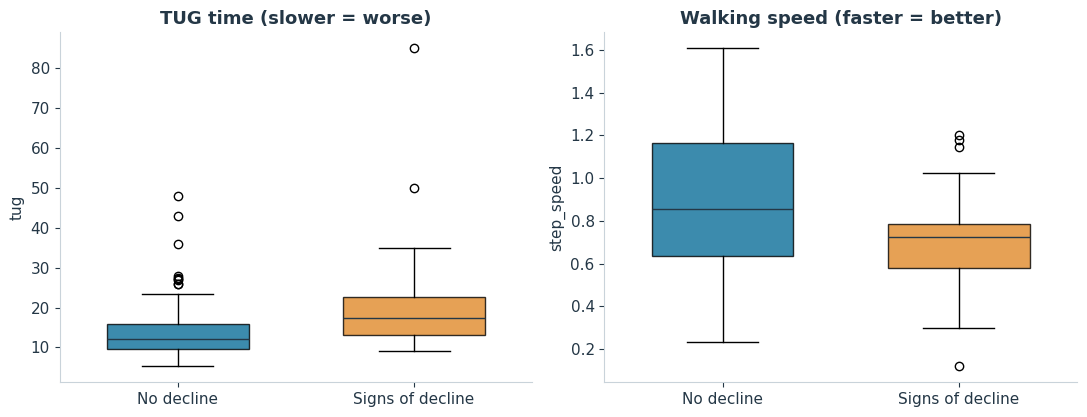

The decline group takes clearly longer on TUG and walks slower. The signal is real,
and visible before we build anything.


In [12]:
yd = TARGETS["Dementia"]
Xf = X.fillna(X.median())
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, feat, nice in zip(axes, ["tug","step_speed"], ["TUG time (slower = worse)","Walking speed (faster = better)"]):
    g0 = Xf.loc[yd==0, feat]; g1 = Xf.loc[yd==1, feat]
    bp = ax.boxplot([g0, g1], labels=["No decline","Signs of decline"], patch_artist=True, widths=0.6)
    for patch, col in zip(bp["boxes"], [PRIMARY, AMBER]): patch.set_facecolor(col); patch.set_alpha(0.8)
    for med in bp["medians"]: med.set_color(INK)
    ax.set_title(nice); ax.set_ylabel(feat); style_ax(ax)
plt.tight_layout(); plt.show()
print("The decline group takes clearly longer on TUG and walks slower. The signal is real,")
print("and visible before we build anything.")

## Step 9 — How we train and test fairly

With only 163 people, a single train/test split would be unreliable, one lucky or unlucky draw could mislead us. So we use **5-fold cross-validation**:

1. Split people into 5 equal groups.
2. Train on 4 groups, test on the 1 left out.
3. Rotate so every group gets a turn as the test set.
4. Average the 5 scores. (We repeat the whole thing 10 times to be safe.)

Below is the idea in one picture: amber = the group tested that round, blue = groups used for training.

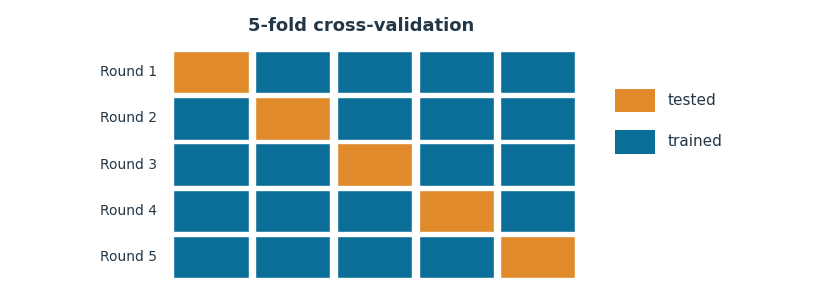

In [13]:
fig, ax = plt.subplots(figsize=(8.5, 3.2))
n=5
for row in range(n):
    for col in range(n):
        ax.add_patch(Rectangle((col, n-1-row), 0.92, 0.92,
                     facecolor=AMBER if col==row else PRIMARY, edgecolor="white"))
    ax.text(-0.2, n-1-row+0.46, f"Round {row+1}", ha="right", va="center", fontsize=10)
ax.text(2.3, n+0.35, "5-fold cross-validation", ha="center", fontsize=13, fontweight="bold")
ax.add_patch(Rectangle((n+0.4, 3.6), 0.5, 0.5, facecolor=AMBER)); ax.text(n+1.05, 3.85, "tested", va="center")
ax.add_patch(Rectangle((n+0.4, 2.7), 0.5, 0.5, facecolor=PRIMARY)); ax.text(n+1.05, 2.95, "trained", va="center")
ax.set_xlim(-2, n+3); ax.set_ylim(-0.4, n+0.8); ax.axis("off")
plt.tight_layout(); plt.show()

In [14]:
# The three algorithms (three different 'styles' of learning)
base = [("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]
def make_models():
    return {
        "Logistic Regression": Pipeline(base + [("m", LogisticRegression(
            C=0.5, class_weight="balanced", max_iter=2000))]),
        "Random Forest": Pipeline(base + [("m", RandomForestClassifier(
            n_estimators=300, min_samples_leaf=3, class_weight="balanced",
            random_state=RANDOM_STATE, n_jobs=-1))]),
        "Gradient Boosting": Pipeline(base + [("m", HistGradientBoostingClassifier(
            max_leaf_nodes=8, learning_rate=0.06, max_iter=150,
            l2_regularization=1.0, random_state=RANDOM_STATE))]),
    }
CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
print("Three algorithms ready:")
print("  1. Logistic Regression - simple and fully explainable")
print("  2. Random Forest        - a voting committee of decision trees")
print("  3. Gradient Boosting    - a perfectionist that fixes its own mistakes")

Three algorithms ready:
  1. Logistic Regression - simple and fully explainable
  2. Random Forest        - a voting committee of decision trees
  3. Gradient Boosting    - a perfectionist that fixes its own mistakes


## Step 10 — Train and compare (3 algorithms x 3 tasks)

We now run every algorithm on every task. The score is **ROC-AUC**: 0.5 is pure guessing, 1.0 is perfect, and around 0.75 is genuinely useful for screening.

**How to read the chart:** taller is better. The thin black lines are the uncertainty, when they overlap, the difference between algorithms is small.

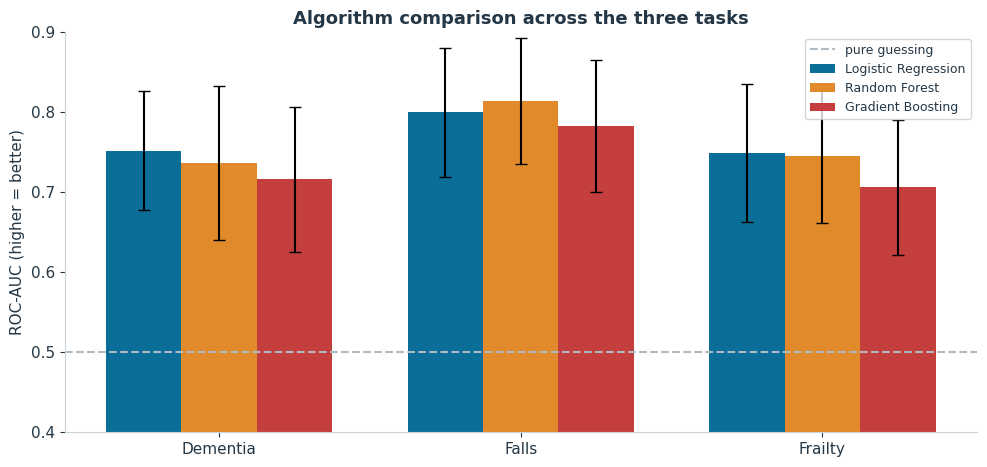

Best algorithm per task:
  Dementia   -> Logistic Regression  AUC 0.752
  Falls      -> Random Forest        AUC 0.814
  Frailty    -> Logistic Regression  AUC 0.749


In [15]:
results = []
for tname, y in TARGETS.items():
    for mname, model in make_models().items():
        r = cross_validate(model, X, y, cv=CV, scoring=["roc_auc","recall"])
        results.append({"task":tname, "algorithm":mname,
                        "auc":r["test_roc_auc"].mean(), "auc_sd":r["test_roc_auc"].std(),
                        "recall":r["test_recall"].mean()})
res = pd.DataFrame(results)

tasks = list(TARGETS); algos = ["Logistic Regression","Random Forest","Gradient Boosting"]
ALGO_COLORS = [PRIMARY, AMBER, POS]      # blue, orange, RED  <-- new
x = np.arange(len(tasks)); w = 0.25
fig, ax = plt.subplots(figsize=(10, 4.8))
for i, a in enumerate(algos):
    vals = [res[(res.task==t)&(res.algorithm==a)].auc.values[0] for t in tasks]
    err  = [res[(res.task==t)&(res.algorithm==a)].auc_sd.values[0] for t in tasks]
    ax.bar(x+(i-1)*w, vals, w, yerr=err, capsize=4, color=ALGO_COLORS[i], label=a)   # <-- changed
ax.axhline(0.5, ls="--", color=GREY, label="pure guessing")
ax.set_xticks(x); ax.set_xticklabels(tasks); ax.set_ylim(0.4, 0.9)
ax.set_ylabel("ROC-AUC (higher = better)"); ax.set_title("Algorithm comparison across the three tasks")
ax.legend(fontsize=9); style_ax(ax); plt.tight_layout(); plt.show()

best = res.sort_values("auc", ascending=False).groupby("task").first()
print("Best algorithm per task:")
for t in tasks:
    b = best.loc[t]; print(f"  {t:<10} -> {b['algorithm']:<20} AUC {b['auc']:.3f}")

**What the chart shows.** The best algorithm differs by task: the **simple Logistic Regression** wins on dementia and frailty (the rarer conditions), while **Random Forest** wins on falls (the balanced one). The error bars overlap, so treat "best" as a gentle lead, not a knockout. The reassuring message: the *simple, explainable* model is right at the top for our main dementia task.

### Step 10b — Nested cross-validation (Reviewer 1, point 5)
Above, we picked the best algorithm using the same CV that scored it, which can flatter the result. Here, an inner loop picks the algorithm using training people only, and an outer loop tests it on unseen people.

Logistic Regression (fixed):  AUC 0.747  (95% CI 0.660 to 0.828)
Nested CV:                    AUC 0.710  (95% CI 0.601 to 0.801)

Times each algorithm was chosen:
  Logistic Regression  29 of 50
  Random Forest        14 of 50
  Gradient Boosting    7 of 50


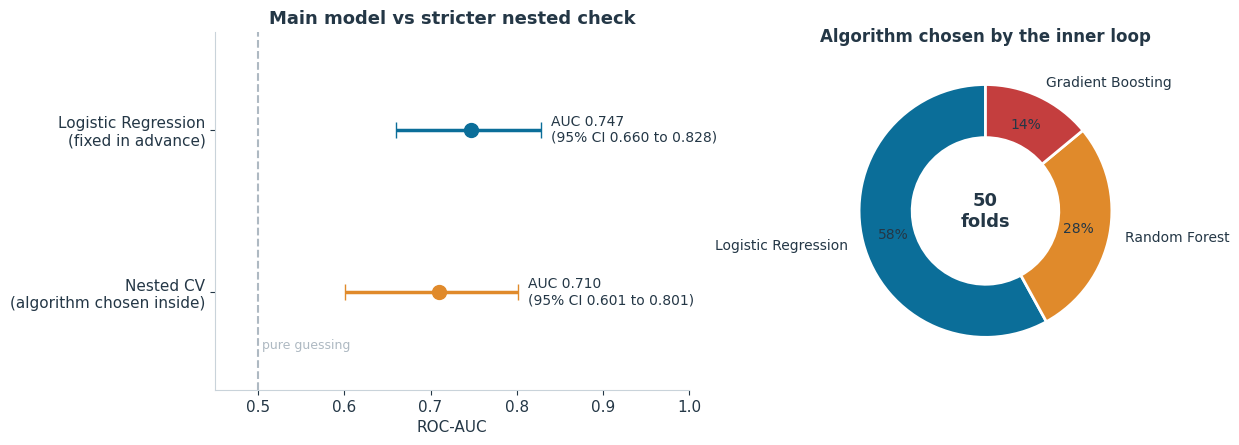

In [20]:
# ===== Step 10b: Nested cross-validation (Reviewer 1, point 5) =====
from sklearn.model_selection import cross_val_score

Xn = X.values.astype(float)
P_nested = np.zeros((N_REPEATS, len(y_cog)))
chosen = []

for r in range(N_REPEATS):
    outer = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE + r)
    for tr, te in outer.split(Xn, y_cog):
        inner = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
        scores = {name: cross_val_score(m, Xn[tr], y_cog[tr], cv=inner, scoring="roc_auc").mean()
                  for name, m in make_models().items()}
        best_name = max(scores, key=scores.get)
        chosen.append(best_name)
        best_model = make_models()[best_name].fit(Xn[tr], y_cog[tr])
        P_nested[r, te] = best_model.predict_proba(Xn[te])[:, 1]

a_nest, lo_nest, hi_nest = auc_with_ci(y_cog, P_nested)
chosen_counts = pd.Series(chosen).value_counts().reindex(make_models().keys(), fill_value=0)

print(f"Logistic Regression (fixed):  AUC {a_fix:.3f}  (95% CI {lo_fix:.3f} to {hi_fix:.3f})")
print(f"Nested CV:                    AUC {a_nest:.3f}  (95% CI {lo_nest:.3f} to {hi_nest:.3f})")
print("\nTimes each algorithm was chosen:")
for name, c in chosen_counts.items():
    print(f"  {name:<20} {c} of {len(chosen)}")

# ===== Step 10b chart: fixed model vs nested CV =====
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})

# Left: AUC with 95% CI
names = ["Logistic Regression\n(fixed in advance)", "Nested CV\n(algorithm chosen inside)"]
pts, los, his = [a_fix, a_nest], [lo_fix, lo_nest], [hi_fix, hi_nest]
for i, (p, l, h, c) in enumerate(zip(pts, los, his, [PRIMARY, AMBER])):
    axes[0].errorbar(p, i, xerr=[[p - l], [h - p]], fmt="o", color=c, ms=10, capsize=6, lw=2.5)
    axes[0].text(h + 0.012, i, f"AUC {p:.3f}\n(95% CI {l:.3f} to {h:.3f})", va="center", fontsize=10)
axes[0].axvline(0.5, ls="--", color=GREY); axes[0].text(0.505, 1.35, "pure guessing", color=GREY, fontsize=9)
axes[0].set_yticks([0, 1]); axes[0].set_yticklabels(names); axes[0].invert_yaxis()
axes[0].set_xlim(0.45, 1.0); axes[0].set_ylim(1.6, -0.6)
axes[0].set_xlabel("ROC-AUC"); axes[0].set_title("Main model vs stricter nested check"); style_ax(axes[0])

# Right: which algorithm the inner loop picked
doughnut(axes[1], chosen_counts.values, list(chosen_counts.index), [PRIMARY, AMBER, POS],
         "Algorithm chosen by the inner loop", f"{len(chosen)}\nfolds")

plt.tight_layout()
fig.savefig("fig_nested_cv.png", dpi=300, bbox_inches="tight")   # for the paper
plt.show()

## Step 11 — A closer look at performance (cognitive decline, GDS 3+)

AUC is one summary number. For a screening tool, three more pictures matter:
- the **ROC curve** (catching cases vs raising false alarms), shown for all 10 repeats,
- the **confusion matrix** at a threshold of **0.5**, fixed in advance and not tuned, and
- the **trade-off at other thresholds**, including **precision** (how many referrals are real cases).

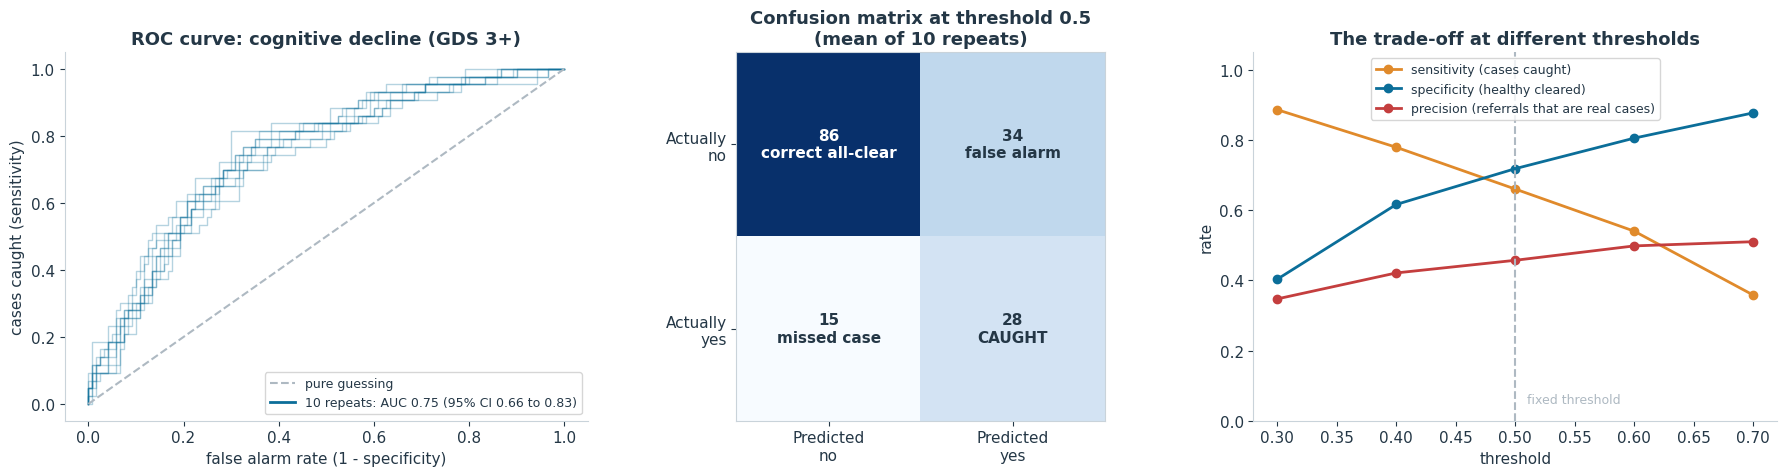

AUC 0.747 (95% CI 0.660 to 0.828), threshold fixed at 0.5
Caught 28 of 43 cases (sensitivity 0.66), specificity 0.72, precision 0.46, 38.2% of people referred


,Threshold,TP,FN,FP,TN,Sensitivity,Specificity,Precision,Referred (%)
0,0.3,38,5,72,48,0.886,0.403,0.347,67.3
1,0.4,34,10,46,74,0.779,0.616,0.421,48.8
2,0.5,28,15,34,86,0.660,0.718,0.457,38.2
3,0.6,23,20,23,97,0.540,0.805,0.498,28.6
4,0.7,15,28,15,105,0.358,0.877,0.510,18.5


In [21]:
# ===== Step 11 (revised): performance over 10 repeats, threshold stated (R1 #7, #8; R2) =====
y = TARGETS["Dementia"]      # kept, because Step 12 uses `y`
THRESHOLD = 0.5              # fixed in advance (class-balanced logistic regression), NOT tuned
P_main = P_fixed             # out-of-fold risk scores from Step 6b (10 repeats x 163 people)

a_main, lo_main, hi_main = auc_with_ci(y_cog, P_main)
st = screen_stats(y_cog, P_main, THRESHOLD)
thr_table = pd.DataFrame([dict(Threshold=t, **screen_stats(y_cog, P_main, t))
                          for t in [0.3, 0.4, 0.5, 0.6, 0.7]])

fig, axes = plt.subplots(1, 3, figsize=(18, 4.9))

# 1) ROC curve: one thin line per repeat
for p in P_main:
    f, t, _ = roc_curve(y_cog, p)
    axes[0].plot(f, t, color=PRIMARY, alpha=0.3, lw=1)
axes[0].plot([0, 1], [0, 1], ls="--", color=GREY, label="pure guessing")
axes[0].plot([], [], color=PRIMARY, lw=2,
             label=f"10 repeats: AUC {a_main:.2f} (95% CI {lo_main:.2f} to {hi_main:.2f})")
axes[0].set_xlabel("false alarm rate (1 - specificity)"); axes[0].set_ylabel("cases caught (sensitivity)")
axes[0].set_title("ROC curve: cognitive decline (GDS 3+)"); axes[0].legend(fontsize=9, loc="lower right")
style_ax(axes[0])

# 2) Confusion matrix at the fixed threshold (average of 10 repeats)
cm = np.array([[st["TN"], st["FP"]], [st["FN"], st["TP"]]])
axes[1].imshow(cm, cmap="Blues")
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(["Predicted\nno", "Predicted\nyes"])
axes[1].set_yticks([0, 1]); axes[1].set_yticklabels(["Actually\nno", "Actually\nyes"])
labels = [["correct all-clear", "false alarm"], ["missed case", "CAUGHT"]]
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, f"{cm[i, j]}\n{labels[i][j]}", ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else INK, fontsize=11, fontweight="bold")
axes[1].set_title(f"Confusion matrix at threshold {THRESHOLD}\n(mean of 10 repeats)")

# 3) What happens at other thresholds
axes[2].plot(thr_table.Threshold, thr_table.Sensitivity, "o-", color=AMBER, lw=2, label="sensitivity (cases caught)")
axes[2].plot(thr_table.Threshold, thr_table.Specificity, "o-", color=PRIMARY, lw=2, label="specificity (healthy cleared)")
axes[2].plot(thr_table.Threshold, thr_table.Precision, "o-", color=POS, lw=2, label="precision (referrals that are real cases)")
axes[2].axvline(THRESHOLD, ls="--", color=GREY)
axes[2].text(THRESHOLD + 0.01, 0.05, "fixed threshold", color=GREY, fontsize=9)
axes[2].set_ylim(0, 1.05); axes[2].set_xlabel("threshold"); axes[2].set_ylabel("rate")
axes[2].set_title("The trade-off at different thresholds"); axes[2].legend(fontsize=9); style_ax(axes[2])

plt.tight_layout()
fig.savefig("fig_performance.png", dpi=300, bbox_inches="tight")   # for the paper
plt.show()

print(f"AUC {a_main:.3f} (95% CI {lo_main:.3f} to {hi_main:.3f}), threshold fixed at {THRESHOLD}")
print(f"Caught {st['TP']} of {st['TP'] + st['FN']} cases (sensitivity {st['Sensitivity']:.2f}), "
      f"specificity {st['Specificity']:.2f}, precision {st['Precision']:.2f}, "
      f"{st['Referred (%)']}% of people referred")
display(thr_table)

### Step 11b — Is the sensor worth it? (ablation)
Reviewers asked whether the foot sensor adds anything beyond the Timed Up and Go (TUG) time, which clinics already measure. We train the same model on different sets of measurements and compare them. A model on TUG alone also acts as a simple clinical rule (a TUG cut-off).

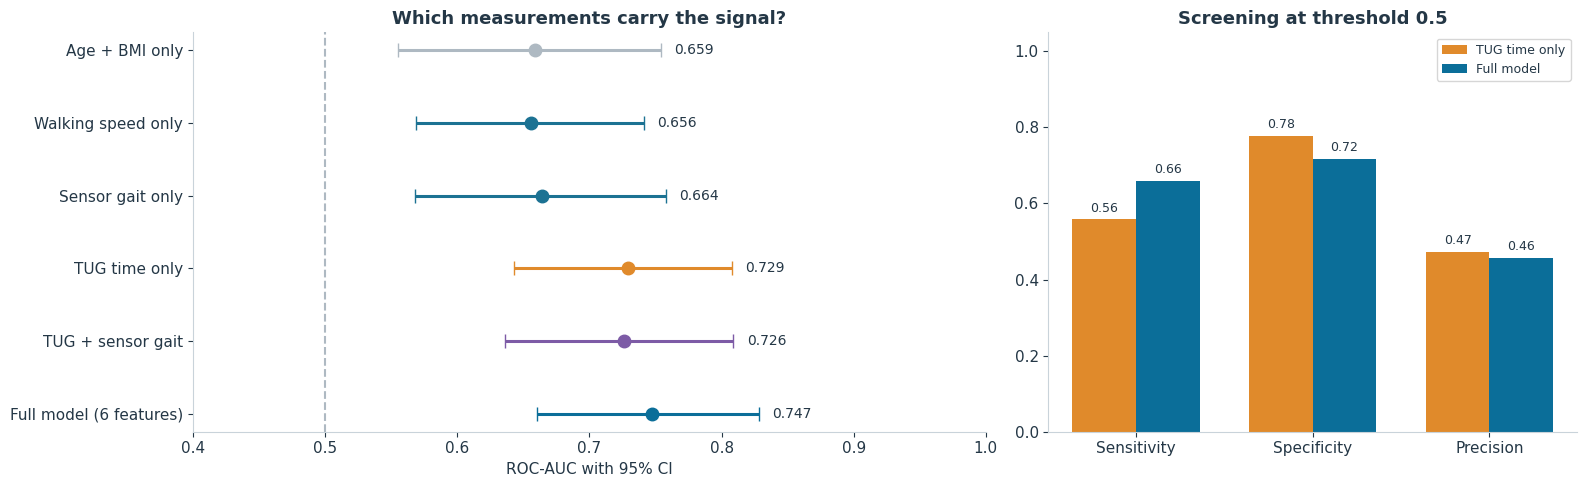

,Model,Features,AUC,CI low,CI high,Sensitivity,Specificity,Precision,Referred (%)
0,Age + BMI only,2,0.659,0.555,0.754,0.635,0.639,0.387,43.3
1,Walking speed only,1,0.656,0.569,0.741,0.733,0.584,0.387,49.9
2,Sensor gait only,3,0.664,0.568,0.758,0.737,0.561,0.376,51.8
3,TUG time only,1,0.729,0.643,0.808,0.558,0.778,0.473,31.1
4,TUG + sensor gait,4,0.726,0.636,0.809,0.660,0.689,0.432,40.3
5,Full model (6 features),6,0.747,0.660,0.828,0.660,0.718,0.457,38.2



Adding sensor gait to TUG:        AUC change -0.003 (95% CI -0.062 to +0.051)
Adding sensor gait + age + BMI:   AUC change +0.018 (95% CI -0.071 to +0.097)
If a CI includes 0, the extra measurements did not clearly improve on TUG alone.


In [22]:
# ===== Step 11b: Is the sensor worth it? Ablation (R1 #8, #9, #10; R2; R3 #3) =====
SETS = {
    "Age + BMI only":            ["age", "bmi"],
    "Walking speed only":        ["step_speed"],
    "Sensor gait only":          ["step_speed", "clearance", "stridetime_std"],
    "TUG time only":             ["tug"],
    "TUG + sensor gait":         ["tug", "step_speed", "clearance", "stridetime_std"],
    "Full model (6 features)":   FEATURES,
}
P_sets = {name: (P_fixed if cols == FEATURES else run_cv(lr_pipeline(), cand[cols], y_cog))
          for name, cols in SETS.items()}

rows = []
for name, P in P_sets.items():
    a, lo, hi = auc_with_ci(y_cog, P)
    rows.append({"Model": name, "Features": len(SETS[name]), "AUC": round(a, 3),
                 "CI low": round(lo, 3), "CI high": round(hi, 3),
                 **screen_stats(y_cog, P, THRESHOLD)})
ablation = pd.DataFrame(rows)

# What do the extra measurements ADD on top of TUG alone?
g1 = auc_gain_ci(y_cog, P_sets["TUG time only"], P_sets["TUG + sensor gait"])
g2 = auc_gain_ci(y_cog, P_sets["TUG time only"], P_sets["Full model (6 features)"])

# ---- chart ----
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1.5, 1]})
cols_ = [GREY, TEAL, TEAL, AMBER, PURPLE, PRIMARY]
for i, r in ablation.iterrows():
    axes[0].errorbar(r["AUC"], i, xerr=[[r["AUC"] - r["CI low"]], [r["CI high"] - r["AUC"]]],
                     fmt="o", color=cols_[i], ms=9, capsize=5, lw=2.2)
    axes[0].text(r["CI high"] + 0.01, i, f"{r['AUC']:.3f}", va="center", fontsize=10)
axes[0].axvline(0.5, ls="--", color=GREY)
axes[0].set_yticks(range(len(ablation))); axes[0].set_yticklabels(ablation["Model"]); axes[0].invert_yaxis()
axes[0].set_xlim(0.4, 1.0); axes[0].set_xlabel("ROC-AUC with 95% CI")
axes[0].set_title("Which measurements carry the signal?"); style_ax(axes[0])

pick = ablation.set_index("Model").loc[["TUG time only", "Full model (6 features)"]]
metrics = ["Sensitivity", "Specificity", "Precision"]
xx = np.arange(len(metrics)); w = 0.36
axes[1].bar(xx - w/2, pick.loc["TUG time only", metrics], w, color=AMBER, label="TUG time only")
axes[1].bar(xx + w/2, pick.loc["Full model (6 features)", metrics], w, color=PRIMARY, label="Full model")
for k, m in enumerate(metrics):
    axes[1].text(k - w/2, pick.loc["TUG time only", m] + 0.02, f"{pick.loc['TUG time only', m]:.2f}", ha="center", fontsize=9)
    axes[1].text(k + w/2, pick.loc["Full model (6 features)", m] + 0.02, f"{pick.loc['Full model (6 features)', m]:.2f}", ha="center", fontsize=9)
axes[1].set_xticks(xx); axes[1].set_xticklabels(metrics); axes[1].set_ylim(0, 1.05)
axes[1].set_title(f"Screening at threshold {THRESHOLD}"); axes[1].legend(fontsize=9); style_ax(axes[1])

plt.tight_layout()
fig.savefig("fig_ablation.png", dpi=300, bbox_inches="tight")   # for the paper
plt.show()

display(ablation[["Model", "Features", "AUC", "CI low", "CI high", "Sensitivity", "Specificity", "Precision", "Referred (%)"]])
print(f"\nAdding sensor gait to TUG:        AUC change {g1[0]:+.3f} (95% CI {g1[1]:+.3f} to {g1[2]:+.3f})")
print(f"Adding sensor gait + age + BMI:   AUC change {g2[0]:+.3f} (95% CI {g2[1]:+.3f} to {g2[2]:+.3f})")
print("If a CI includes 0, the extra measurements did not clearly improve on TUG alone.")

### Step 11c — Can the risk score be read as a probability? (calibration)
AUC shows whether the model **ranks** people well. Calibration shows whether the **numbers** are right: if the model says 40% risk, do about 40% of those people really have GDS 3+? We report the Brier score, calibration intercept and slope, and a calibration plot.

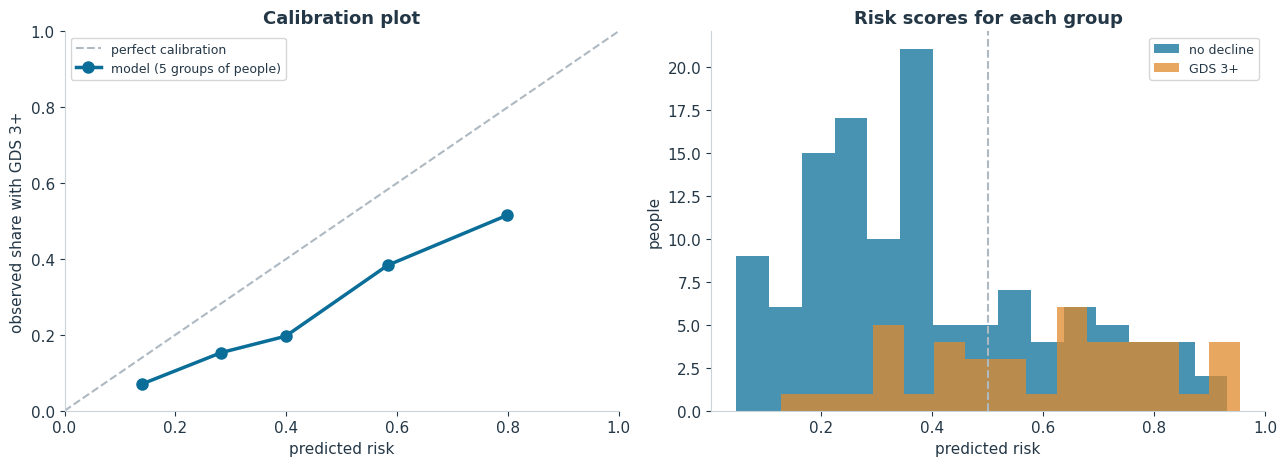

Brier score:            0.202   (no-skill reference 0.194; lower is better)
Calibration intercept:  -1.017   (0 = perfect; below 0 = risks too high)
Calibration slope:      0.786   (1 = perfect; below 1 = risks too extreme)
Mean predicted risk:    0.441   vs   true share with GDS 3+: 0.264


In [23]:
# ===== Step 11c: Calibration, can the risk score be read as a probability? (R1 #13) =====
eps = 1e-6
prev = y_cog.mean()                                    # true share with GDS 3+
brier = np.mean([brier_score_loss(y_cog, p) for p in P_main])
brier_ref = brier_score_loss(y_cog, np.full(len(y_cog), prev))   # "no-skill" model: everyone gets the average risk

slopes, intercepts = [], []
for p in P_main:
    lp = np.log(np.clip(p, eps, 1 - eps) / (1 - np.clip(p, eps, 1 - eps)))
    slopes.append(sm.Logit(y_cog, sm.add_constant(lp)).fit(disp=0).params[1])
    intercepts.append(sm.GLM(y_cog, np.ones((len(y_cog), 1)), family=sm.families.Binomial(),
                             offset=lp).fit().params[0])
slope, intercept = np.mean(slopes), np.mean(intercepts)

# pool the 10 repeats for the plot
y_rep, p_rep = np.tile(y_cog, len(P_main)), P_main.ravel()
frac_pos, mean_pred = calibration_curve(y_rep, p_rep, n_bins=5, strategy="quantile")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot([0, 1], [0, 1], ls="--", color=GREY, label="perfect calibration")
axes[0].plot(mean_pred, frac_pos, "o-", color=PRIMARY, lw=2.5, ms=8, label="model (5 groups of people)")
axes[0].set_xlim(0, 1); axes[0].set_ylim(0, 1)
axes[0].set_xlabel("predicted risk"); axes[0].set_ylabel("observed share with GDS 3+")
axes[0].set_title("Calibration plot"); axes[0].legend(fontsize=9); style_ax(axes[0])

axes[1].hist(P_main.mean(0)[y_cog == 0], bins=15, alpha=0.75, color=PRIMARY, label="no decline")
axes[1].hist(P_main.mean(0)[y_cog == 1], bins=15, alpha=0.75, color=AMBER, label="GDS 3+")
axes[1].axvline(THRESHOLD, ls="--", color=GREY)
axes[1].set_xlabel("predicted risk"); axes[1].set_ylabel("people")
axes[1].set_title("Risk scores for each group"); axes[1].legend(fontsize=9); style_ax(axes[1])

plt.tight_layout()
fig.savefig("fig_calibration.png", dpi=300, bbox_inches="tight")   # for the paper
plt.show()

print(f"Brier score:            {brier:.3f}   (no-skill reference {brier_ref:.3f}; lower is better)")
print(f"Calibration intercept:  {intercept:+.3f}   (0 = perfect; below 0 = risks too high)")
print(f"Calibration slope:      {slope:.3f}   (1 = perfect; below 1 = risks too extreme)")
print(f"Mean predicted risk:    {p_rep.mean():.3f}   vs   true share with GDS 3+: {prev:.3f}")

### Step 11d — Does the model find mild cases, or only severe ones?
Our outcome groups everyone with GDS 3 or more together. A reviewer asked whether the model picks up **mild** decline (GDS 3) or mainly separates people with **more advanced** decline (GDS 4+). We show the share flagged at each stage, and the AUC for each group against people with GDS 1 to 2.

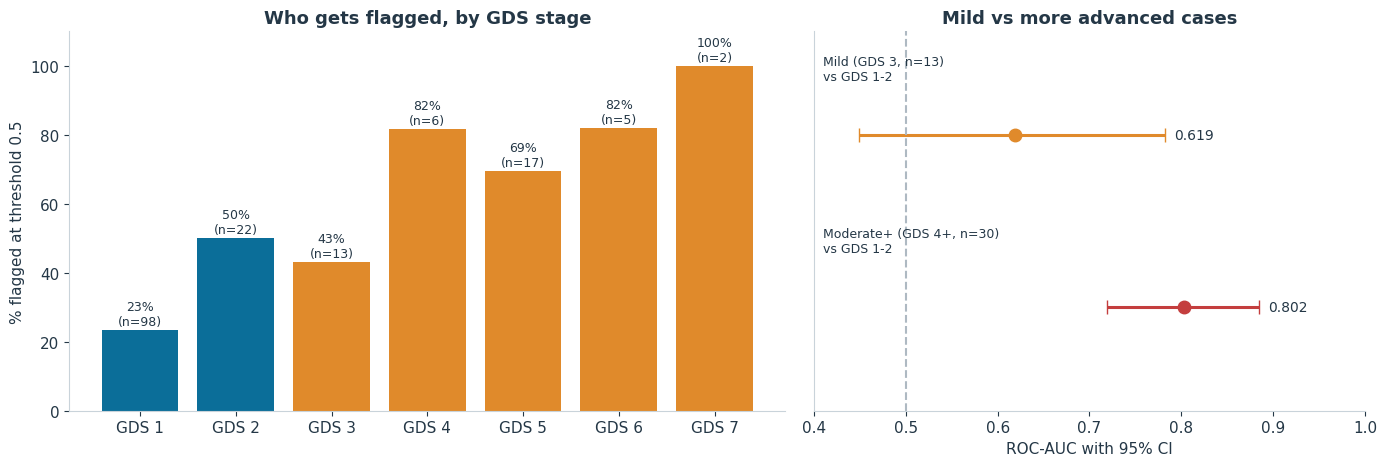

,People,Mean_risk,Flagged_pct
GDS,,,
1,98,0.35,23.27
2,22,0.53,50.00
3,13,0.48,43.08
4,6,0.66,81.67
5,17,0.59,69.41
6,5,0.70,82.00
7,2,0.88,100.00


Mild (GDS 3) vs GDS 1-2:       AUC 0.619 (95% CI 0.449 to 0.782), n=13
Moderate+ (GDS 4+) vs GDS 1-2: AUC 0.802 (95% CI 0.720 to 0.884), n=30


In [24]:
# ===== Step 11d: Does the model find mild cases, or only severe ones? (R1 #12) =====
g = pd.to_numeric(gds, errors="coerce").values            # GDS stage from Step 3
risk = P_main.mean(0)                                     # each person's average risk score
flag = (P_main >= THRESHOLD).mean(0)                      # share of repeats each person was flagged

stage = pd.DataFrame({"GDS": g, "risk": risk, "flag": flag}).dropna(subset=["GDS"])
by_stage = stage.groupby("GDS").agg(People=("risk", "size"),
                                    Mean_risk=("risk", "mean"),
                                    Flagged_pct=("flag", lambda s: 100 * s.mean())).round(2)

def stage_auc(pos_mask):
    """AUC for one group of cases vs people with GDS 1-2 only."""
    keep = ~np.isnan(g) & ((g <= 2) | pos_mask)
    yy = pos_mask[keep].astype(int)
    return auc_with_ci(yy, P_main[:, keep]) if 0 < yy.sum() < len(yy) else (np.nan, np.nan, np.nan)

auc_mild = stage_auc(g == 3)       # mild decline
auc_adv  = stage_auc(g >= 4)       # moderate or worse
n_mild, n_adv = int(np.nansum(g == 3)), int(np.nansum(g >= 4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
labels = [f"GDS {int(s)}" for s in by_stage.index]
cols_ = [AMBER if s >= 3 else PRIMARY for s in by_stage.index]
axes[0].bar(labels, by_stage["Flagged_pct"], color=cols_)
for i, (v, n) in enumerate(zip(by_stage["Flagged_pct"], by_stage["People"])):
    axes[0].text(i, v + 1.5, f"{v:.0f}%\n(n={n})", ha="center", fontsize=9)
axes[0].set_ylim(0, 110); axes[0].set_ylabel(f"% flagged at threshold {THRESHOLD}")
axes[0].set_title("Who gets flagged, by GDS stage"); style_ax(axes[0])

for i, (name, (a, lo, hi), c) in enumerate([(f"Mild (GDS 3, n={n_mild})\nvs GDS 1-2", auc_mild, AMBER),
                                            (f"Moderate+ (GDS 4+, n={n_adv})\nvs GDS 1-2", auc_adv, POS)]):
    if not np.isnan(a):
        axes[1].errorbar(a, i, xerr=[[a - lo], [hi - a]], fmt="o", color=c, ms=9, capsize=5, lw=2.2)
        axes[1].text(hi + 0.01, i, f"{a:.3f}", va="center", fontsize=10)
    axes[1].text(0.41, i - 0.32, name, fontsize=9)
axes[1].axvline(0.5, ls="--", color=GREY)
axes[1].set_yticks([]); axes[1].set_ylim(1.6, -0.6); axes[1].set_xlim(0.4, 1.0)
axes[1].set_xlabel("ROC-AUC with 95% CI"); axes[1].set_title("Mild vs more advanced cases"); style_ax(axes[1])

plt.tight_layout()
fig.savefig("fig_gds_stage.png", dpi=300, bbox_inches="tight")   # for the paper
plt.show()

display(by_stage)
print(f"Mild (GDS 3) vs GDS 1-2:       AUC {auc_mild[0]:.3f} (95% CI {auc_mild[1]:.3f} to {auc_mild[2]:.3f}), n={n_mild}")
print(f"Moderate+ (GDS 4+) vs GDS 1-2: AUC {auc_adv[0]:.3f} (95% CI {auc_adv[1]:.3f} to {auc_adv[2]:.3f}), n={n_adv}")

## Step 12 — What did the model learn? (odds ratios with 95% CIs)

We show **odds ratios per 1 standard deviation (SD)** of each measurement, with **95% confidence intervals**:
- **CI fully above 1** (red) = a higher value clearly raises the odds of decline
- **CI fully below 1** (blue) = a higher value clearly lowers the odds
- **CI crossing 1** (grey) = no clear effect

The model is fitted on all 163 people using the 6 features from Step 6. Step 6b showed that this feature set is chosen in every training fold, so the choice does not depend on the outcome. We also give bootstrap CIs (1,000 resamples) as a check.

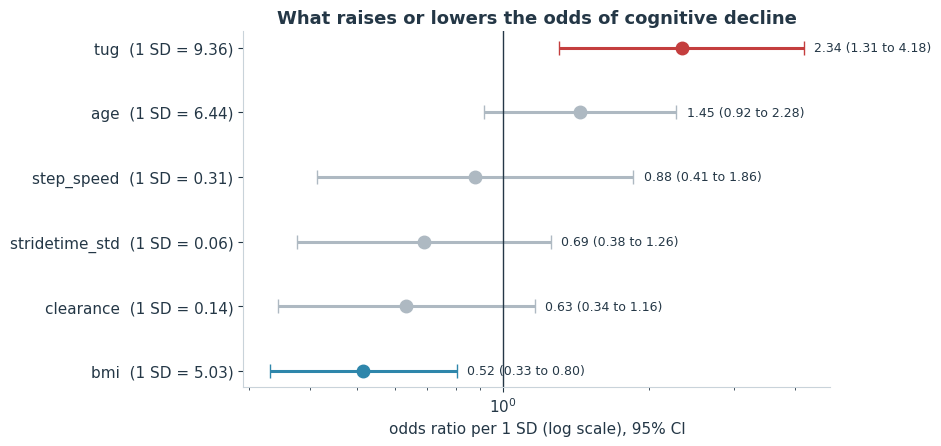

,feature,1 SD (real units),OR per 1 SD,CI low,CI high,p,Boot low,Boot high
0,bmi,5.03,0.517,0.332,0.804,0.003,0.294,0.763
1,clearance,0.14,0.633,0.344,1.165,0.141,0.143,1.138
2,stridetime_std,0.06,0.688,0.376,1.257,0.224,0.331,1.298
3,step_speed,0.31,0.879,0.415,1.862,0.736,0.405,1.998
4,age,6.44,1.447,0.917,2.283,0.113,0.844,2.565
5,tug,9.36,2.339,1.310,4.177,0.004,1.425,5.967


Red = CI fully above 1 (raises odds). Blue = CI fully below 1 (lowers odds). Grey = CI crosses 1 (not clear).
Odds ratios are per 1 standard deviation of each measurement (see the '1 SD' column).


In [25]:
# ===== Step 12 (revised): odds ratios per 1 SD, with 95% CIs (R1 #11; R2) =====
Xi = X.fillna(X.median())
sd = Xi.std()                                             # 1 SD in real units, for interpretation
Xz = pd.DataFrame(StandardScaler().fit_transform(Xi), columns=FEATURES)
mdl = sm.Logit(y.values, sm.add_constant(Xz)).fit(disp=0)
ci = np.exp(mdl.conf_int().loc[FEATURES])

odds = pd.DataFrame({"feature": FEATURES,
                     "1 SD (real units)": sd[FEATURES].round(2).values,
                     "OR per 1 SD": np.exp(mdl.params[FEATURES]).values,
                     "CI low": ci[0].values, "CI high": ci[1].values,
                     "p": mdl.pvalues[FEATURES].values})

# Bootstrap CI: refit the model on 1,000 resamples of the people (a check that does not rely on formulas)
rng = np.random.default_rng(RANDOM_STATE); boot = []
for _ in range(1000):
    i = rng.integers(0, len(Xz), len(Xz))
    try:
        b = sm.Logit(y.values[i], sm.add_constant(Xz.iloc[i].reset_index(drop=True), has_constant="add")).fit(disp=0)
        boot.append(np.exp(b.params[FEATURES].values))
    except Exception:
        pass
boot = np.array(boot)
odds["Boot low"], odds["Boot high"] = np.percentile(boot, 2.5, axis=0), np.percentile(boot, 97.5, axis=0)
odds = odds.sort_values("OR per 1 SD").reset_index(drop=True)

# ---- forest plot ----
fig, ax = plt.subplots(figsize=(9.5, 4.6))
for k, r in odds.iterrows():
    c = POS if r["CI low"] > 1 else (NEG if r["CI high"] < 1 else GREY)
    ax.errorbar(r["OR per 1 SD"], k, xerr=[[r["OR per 1 SD"] - r["CI low"]], [r["CI high"] - r["OR per 1 SD"]]],
                fmt="o", color=c, ms=9, capsize=5, lw=2.2)
    ax.text(r["CI high"] * 1.05, k, f"{r['OR per 1 SD']:.2f} ({r['CI low']:.2f} to {r['CI high']:.2f})",
            va="center", fontsize=9)
ax.axvline(1, color=INK, lw=1)
ax.set_xscale("log")
ax.set_yticks(range(len(odds)))
ax.set_yticklabels([f"{f}  (1 SD = {s})" for f, s in zip(odds["feature"], odds["1 SD (real units)"])])
ax.set_xlabel("odds ratio per 1 SD (log scale), 95% CI")
ax.set_title("What raises or lowers the odds of cognitive decline"); style_ax(ax)
plt.tight_layout()
fig.savefig("fig_odds_ratios.png", dpi=300, bbox_inches="tight")   # for the paper
plt.show()

display(odds.round(3))
print("Red = CI fully above 1 (raises odds). Blue = CI fully below 1 (lowers odds). Grey = CI crosses 1 (not clear).")
print("Odds ratios are per 1 standard deviation of each measurement (see the '1 SD' column).")

**The headline:** a **slower Timed Up and Go** is the only clear risk signal (OR 2.34 per 9.4 s, 95% CI 1.31 to 4.18). **Lower BMI** is also linked to higher odds (OR 0.52 per 5 kg/m², 95% CI 0.33 to 0.80), which may reflect weight loss that often comes with cognitive decline. The sensor gait measures (speed, clearance, stride-time variability) point in sensible directions, but their confidence intervals all cross 1, so they show **no clear independent effect** once TUG and BMI are in the model.

## Step 13 — How do the three tasks relate?

We used the **same walking measurements** for all three tasks. Do they flag the same people? We check this in three ways:
- **Risk scores:** a heatmap of how strongly the three model risk scores agree, and a scatter of dementia vs frailty risk.
- **A) Real labels:** high agreement between risk scores can simply come from the models sharing the same inputs, so we also compare the **real labels** (correlation, kappa and % agreement).
- **B) Gait beyond frailty:** we compare a model with frailty, falls and age against the same model with TUG, gait and BMI added, and report adjusted odds ratios.

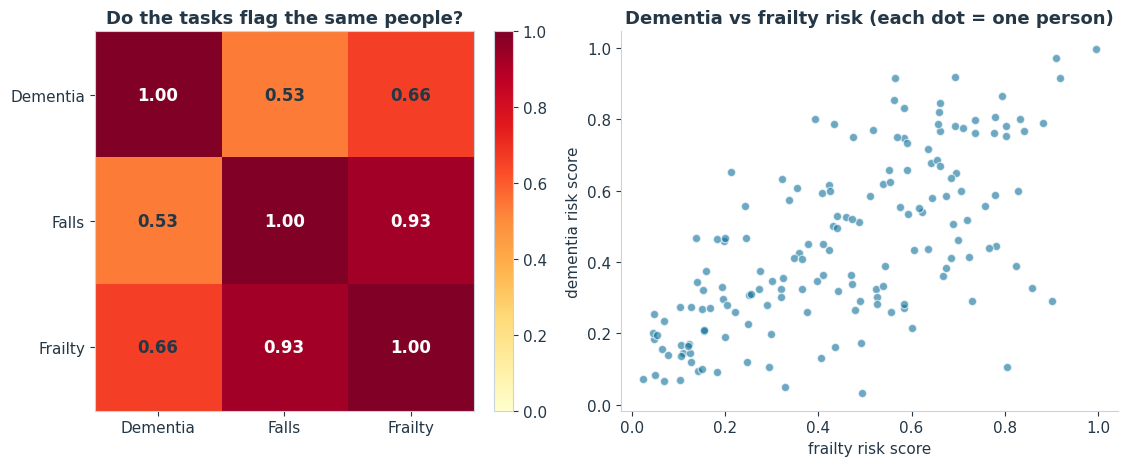

Falls and frailty model scores agree strongly (~0.9), but this mostly reflects shared inputs (see Part A below).
Cognitive-decline scores agree only moderately (~0.5 to 0.7) with the physical tasks.


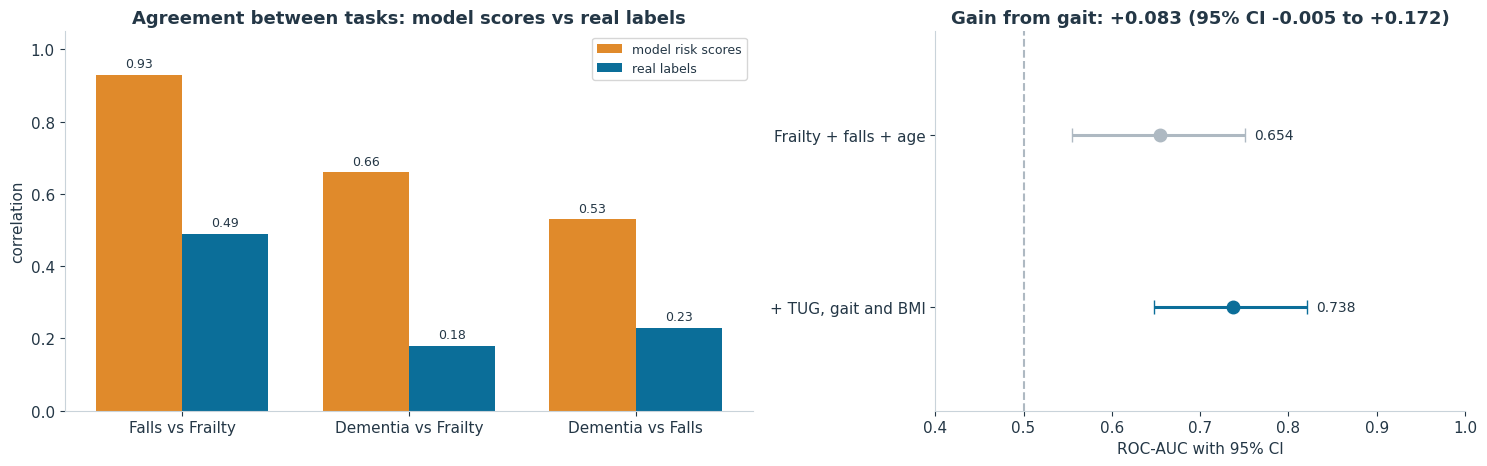

PART A: agreement between tasks


,Pair,Model-score correlation,Real-label correlation (phi),Real-label kappa,Real-label agreement (%)
0,Falls vs Frailty,0.93,0.49,0.44,71.2
1,Dementia vs Frailty,0.66,0.18,0.18,66.9
2,Dementia vs Falls,0.53,0.23,0.20,58.9



PART B: Frailty + falls + age:       AUC 0.654 (95% CI 0.555 to 0.751)
        + TUG, gait and BMI:         AUC 0.738 (95% CI 0.648 to 0.821)
        Gain from gait:              +0.083 (95% CI -0.005 to +0.172)

Adjusted odds ratios (continuous = per 1 SD; frailty and falls = yes vs no):


,OR (adjusted),CI low,CI high,p
frailty,1.126,0.444,2.856,0.803
falls,2.177,0.831,5.703,0.113
age,1.432,0.895,2.291,0.135
tug,2.223,1.280,3.859,0.005
step_speed,0.989,0.467,2.092,0.977
clearance,0.650,0.346,1.220,0.180
stridetime_std,0.669,0.371,1.208,0.183
bmi,0.493,0.315,0.773,0.002


In [29]:
# ===== Step 13 (revised): how the tasks relate, real labels, and gait beyond frailty =====
probs = {}
for tname, yy in TARGETS.items():
    probs[tname] = cross_val_predict(make_models()["Logistic Regression"], X, yy,
                    cv=StratifiedKFold(5, shuffle=True, random_state=1), method="predict_proba")[:,1]
names = list(TARGETS)
M = np.array([[pearsonr(probs[a], probs[b])[0] for b in names] for a in names])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
im = axes[0].imshow(M, cmap="YlOrRd", vmin=0, vmax=1)
axes[0].set_xticks(range(3)); axes[0].set_xticklabels(names)
axes[0].set_yticks(range(3)); axes[0].set_yticklabels(names)
for i in range(3):
    for j in range(3):
        axes[0].text(j, i, f"{M[i,j]:.2f}", ha="center", va="center",
                     color="white" if M[i,j]>0.7 else INK, fontsize=12, fontweight="bold")
axes[0].set_title("Do the tasks flag the same people?")
plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)

axes[1].scatter(probs["Frailty"], probs["Dementia"], c=PRIMARY, alpha=0.6, edgecolor="white")
axes[1].set_xlabel("frailty risk score"); axes[1].set_ylabel("dementia risk score")
axes[1].set_title("Dementia vs frailty risk (each dot = one person)"); style_ax(axes[1])
plt.tight_layout(); plt.show()

print("Falls and frailty model scores agree strongly (~0.9), but this mostly reflects shared inputs (see Part A below).")
print("Cognitive-decline scores agree only moderately (~0.5 to 0.7) with the physical tasks.")

# ===== Part A and B: real labels, and gait beyond frailty (R1 #3, #4) =====
from sklearn.metrics import cohen_kappa_score
lab = pd.DataFrame({k: np.asarray(v).astype(int) for k, v in TARGETS.items()})

# ---- Part A (R1 #4): do the REAL labels agree, or only the model scores? ----
rows = []
for a, b in [("Falls", "Frailty"), ("Dementia", "Frailty"), ("Dementia", "Falls")]:
    rows.append({"Pair": f"{a} vs {b}",
                 "Model-score correlation": round(pearsonr(probs[a], probs[b])[0], 2),
                 "Real-label correlation (phi)": round(pearsonr(lab[a], lab[b])[0], 2),
                 "Real-label kappa": round(cohen_kappa_score(lab[a], lab[b]), 2),
                 "Real-label agreement (%)": round(100 * (lab[a] == lab[b]).mean(), 1)})
agree = pd.DataFrame(rows)

# ---- Part B (R1 #3): does gait add anything beyond frailty, falls and age? ----
gait_cols = ["tug", "step_speed", "clearance", "stridetime_std", "bmi"]
base_df = pd.DataFrame({"frailty": lab["Frailty"], "falls": lab["Falls"],
                        "age": cand["age"].reset_index(drop=True)})
plus_df = pd.concat([base_df, cand[gait_cols].reset_index(drop=True)], axis=1)

P_base = run_cv(lr_pipeline(), base_df, y_cog)
P_plus = run_cv(lr_pipeline(), plus_df, y_cog)
a_b = auc_with_ci(y_cog, P_base); a_p = auc_with_ci(y_cog, P_plus)
gain = auc_gain_ci(y_cog, P_base, P_plus)

# adjusted odds ratios: each gait measure, holding frailty, falls and age fixed
Z = plus_df.fillna(plus_df.median())
cont = ["age"] + gait_cols
Zs = Z.copy(); Zs[cont] = StandardScaler().fit_transform(Z[cont])   # per 1 SD (frailty/falls stay 0/1)
adj = sm.Logit(y_cog, sm.add_constant(Zs)).fit(disp=0)
adj_ci = np.exp(adj.conf_int())
adj_tab = pd.DataFrame({"OR (adjusted)": np.exp(adj.params), "CI low": adj_ci[0], "CI high": adj_ci[1],
                        "p": adj.pvalues}).drop("const").round(3)

# ---- chart ----
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
xx = np.arange(len(agree)); w = 0.38
axes[0].bar(xx - w/2, agree["Model-score correlation"], w, color=AMBER, label="model risk scores")
axes[0].bar(xx + w/2, agree["Real-label correlation (phi)"], w, color=PRIMARY, label="real labels")
for k in range(len(agree)):
    axes[0].text(k - w/2, agree["Model-score correlation"][k] + 0.02, f"{agree['Model-score correlation'][k]:.2f}", ha="center", fontsize=9)
    axes[0].text(k + w/2, agree["Real-label correlation (phi)"][k] + 0.02, f"{agree['Real-label correlation (phi)'][k]:.2f}", ha="center", fontsize=9)
axes[0].set_xticks(xx); axes[0].set_xticklabels(agree["Pair"]); axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("correlation"); axes[0].set_title("Agreement between tasks: model scores vs real labels")
axes[0].legend(fontsize=9); style_ax(axes[0])

for i, (name, (a, lo, hi), c) in enumerate([("Frailty + falls + age", a_b, GREY),
                                            ("+ TUG, gait and BMI", a_p, PRIMARY)]):
    axes[1].errorbar(a, i, xerr=[[a - lo], [hi - a]], fmt="o", color=c, ms=9, capsize=5, lw=2.2)
    axes[1].text(hi + 0.01, i, f"{a:.3f}", va="center", fontsize=10)
axes[1].axvline(0.5, ls="--", color=GREY)
axes[1].set_yticks([0, 1]); axes[1].set_yticklabels(["Frailty + falls + age", "+ TUG, gait and BMI"])
axes[1].set_ylim(1.6, -0.6); axes[1].set_xlim(0.4, 1.0)
axes[1].set_xlabel("ROC-AUC with 95% CI")
axes[1].set_title(f"Gain from gait: {gain[0]:+.3f} (95% CI {gain[1]:+.3f} to {gain[2]:+.3f})"); style_ax(axes[1])

plt.tight_layout()
fig.savefig("fig_beyond_frailty.png", dpi=300, bbox_inches="tight")   # for the paper
plt.show()

print("PART A: agreement between tasks")
display(agree)
print(f"\nPART B: Frailty + falls + age:       AUC {a_b[0]:.3f} (95% CI {a_b[1]:.3f} to {a_b[2]:.3f})")
print(f"        + TUG, gait and BMI:         AUC {a_p[0]:.3f} (95% CI {a_p[1]:.3f} to {a_p[2]:.3f})")
print(f"        Gain from gait:              {gain[0]:+.3f} (95% CI {gain[1]:+.3f} to {gain[2]:+.3f})")
print("\nAdjusted odds ratios (continuous = per 1 SD; frailty and falls = yes vs no):")
display(adj_tab)

## Step 14 — What we found, and its limits

**What we showed**
- A simple, explainable model separates people with GDS 3+ from those without (AUC 0.747, 95% CI 0.660 to 0.828). A stricter nested check gives AUC 0.710.
- At a threshold of 0.5, fixed in advance, it catches 28 of 43 cases (sensitivity 0.66) and refers 38% of people. Precision is 0.46.
- **TUG time carries most of the signal.** TUG alone reaches AUC 0.729. The foot-sensor gait features add no clear gain on top of TUG.
- The model mainly detects **moderate or worse** decline (GDS 4+, AUC 0.802). It does not reliably detect mild decline (GDS 3, AUC 0.619).
- Slower TUG stays linked to cognitive decline after we account for frailty, falls and age (adjusted OR 2.22, 95% CI 1.28 to 3.86). This suggests TUG reflects more than physical frailty. Lower BMI is also linked to higher odds.
- Falls and frailty model scores agree strongly (0.93) because they share the same inputs. The real labels agree only moderately (phi 0.49).

**Honest limits**
- It is a **screening signal, not a diagnosis**. GDS 3+ is a staging threshold, not a dementia diagnosis.
- It is a **snapshot**: walking and cognition were measured at the same time, so this shows association with current stage, not prediction of future decline.
- **Small, single cohort** (163 people, 43 cases), mostly women aged 80+, with no external validation.
- The risk scores are **not calibrated probabilities** (class-balanced weighting), so use them for ranking only.
- Pain, medication, walking aids and other conditions were not controlled for.
- This study tests only the **physical and cognitive** parts of the psychointelligence framework.

**Next steps:** external validation in a larger, more varied cohort, longitudinal follow-up, and recalibration.